# Forward-Facing Sonar and Tournament Outcomes in the Bassmaster Elite Series (2012–2026)

## INSY 7130 Final Project

### Author
Joshua Etherton

# 1. Introduction
### Research Question

Forward-Facing Sonar (FFS) has fundamentally changed competitive bass fishing by allowing anglers to locate and target fish in real time. This project investigates whether tournament-level outcomes differ across periods and tournaments in which FFS was unavailable, unrestricted, restricted, or prohibited.

Specifically, I evaluate associations between FFS availability and:

- Total catch weight
- Number of fish caught
- Average fish weight

I also investigate whether these relationships vary among fisheries (waterbodies) and over time.

# 2. Data Description

The dataset contains Bassmaster Elite Series tournament results from approximately 2012–2026.

Each observation represents a single angler's performance in a tournament.

Key variables include:

- Season_Year
- Tournament_ID
- Event_Name
- Location
- Waterbody
- Allowed_FFS
- Place
- Angler_Name
- Fish_Caught
- Weight_Lbs_Calculated
- Fantasy_Points

Derived Variable:

Average Fish Weight

\[
\text{Avg Fish Weight} =
\frac{\text{Weight (lbs)}}{\text{Fish Caught}}
\]

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("bass_cleaned.csv")

df.head()

,Season_Year,Tournament_ID,Event_Name,Location,Tournament_Dates,Allowed_FFS,Metadata_Source,Place,Angler_Name,Player_ID,Fish_Caught,Weight_Oz,Big_Bag_Points,Big_Bass_Points,Leader_Bonus,Fantasy_Points,Source_URL,Weight_Lbs_Calculated,Weight_Lbs,Weight_Oz_Remainder,Potential_Duplicate,Metadata_Needs_Review,Avg_Fish_Weight,Month,Waterbody
0,2012,1,Bassmaster Classic,"Red River (Shreveport, LA)","Feb 24–26, 2012",No FFS Existed,supplied_inventory_title_match,1,Chris Lane,168,15,822,40.0,NaN,10.0,350,https://bassmasterfantasy.com/TournamentDetail...,51.3750,51.0,6.0,False,True,3.425000,Feb,"Red River (Shreveport, LA)"
1,2012,1,Bassmaster Classic,"Red River (Shreveport, LA)","Feb 24–26, 2012",No FFS Existed,supplied_inventory_title_match,2,Greg Vinson,213,15,767,NaN,NaN,5.0,295,https://bassmasterfantasy.com/TournamentDetail...,47.9375,47.0,15.0,False,True,3.195833,Feb,"Red River (Shreveport, LA)"
2,2012,1,Bassmaster Classic,"Red River (Shreveport, LA)","Feb 24–26, 2012",No FFS Existed,supplied_inventory_title_match,3,Keith Poche,186,15,735,NaN,40.0,10.0,335,https://bassmasterfantasy.com/TournamentDetail...,45.9375,45.0,15.0,False,True,3.062500,Feb,"Red River (Shreveport, LA)"
3,2012,1,Bassmaster Classic,"Red River (Shreveport, LA)","Feb 24–26, 2012",No FFS Existed,supplied_inventory_title_match,4,Alton Jones,130,15,734,NaN,NaN,5.0,285,https://bassmasterfantasy.com/TournamentDetail...,45.8750,45.0,14.0,False,True,3.058333,Feb,"Red River (Shreveport, LA)"
4,2012,1,Bassmaster Classic,"Red River (Shreveport, LA)","Feb 24–26, 2012",No FFS Existed,supplied_inventory_title_match,5,Ott Defoe,149,15,718,NaN,NaN,10.0,280,https://bassmasterfantasy.com/TournamentDetail...,44.8750,44.0,14.0,False,True,2.991667,Feb,"Red River (Shreveport, LA)"


In [3]:
print(df.shape)

df.info()

(13968, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13968 entries, 0 to 13967
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Season_Year            13968 non-null  int64  
 1   Tournament_ID          13968 non-null  int64  
 2   Event_Name             13968 non-null  object 
 3   Location               13968 non-null  object 
 4   Tournament_Dates       12358 non-null  object 
 5   Allowed_FFS            13968 non-null  object 
 6   Metadata_Source        13968 non-null  object 
 7   Place                  13968 non-null  int64  
 8   Angler_Name            13968 non-null  object 
 9   Player_ID              13968 non-null  int64  
 10  Fish_Caught            13968 non-null  int64  
 11  Weight_Oz              13968 non-null  int64  
 12  Big_Bag_Points         153 non-null    float64
 13  Big_Bass_Points        164 non-null    float64
 14  Leader_Bonus           1375 non-null   flo

In [4]:
df.describe(include="all")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Season_Year,Tournament_ID,Event_Name,Location,Tournament_Dates,Allowed_FFS,Metadata_Source,Place,Angler_Name,Player_ID,Fish_Caught,Weight_Oz,Big_Bag_Points,Big_Bass_Points,Leader_Bonus,Fantasy_Points,Source_URL,Weight_Lbs_Calculated,Weight_Lbs,Weight_Oz_Remainder,Potential_Duplicate,Metadata_Needs_Review,Avg_Fish_Weight,Month,Waterbody
count,13968.000000,13968.000000,13968,13968,12358,13968,13968,13968.000000,13968,13968.000000,13968.000000,13968.000000,153.0,164.0,1375.000000,13968.000000,13968,13968.000000,13967.000000,13967.000000,13968,13968,1.393000e+04,12358,13968
unique,NaN,NaN,95,76,126,5,3,NaN,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150,NaN,NaN,NaN,1,1,NaN,9,52
top,NaN,NaN,Elite Series at St. Lawrence River,Unknown Location,"Feb 9–12, 2017",Yes (Unrestricted),supplied_inventory_title_match,NaN,Bill Lowen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://bassmasterfantasy.com/TournamentDetail...,NaN,NaN,NaN,False,True,NaN,Apr,Unknown
freq,NaN,NaN,668,1610,220,8349,11681,NaN,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,113,NaN,NaN,NaN,13968,13968,NaN,2294,1610
mean,2019.080756,5.546392,NaN,NaN,NaN,NaN,NaN,48.855813,NaN,290.079611,11.801332,555.354310,40.0,40.0,5.858182,179.932847,NaN,34.709644,34.246152,7.456791,NaN,NaN,-inf,NaN,NaN
std,4.300159,2.824170,NaN,NaN,NaN,NaN,NaN,29.303044,NaN,114.104682,4.232416,300.236147,0.0,0.0,2.395919,63.652558,NaN,18.764759,18.765513,4.626983,NaN,NaN,NaN,NaN,NaN
min,2012.000000,1.000000,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,117.000000,0.000000,-16.000000,40.0,40.0,5.000000,0.000000,NaN,-1.000000,0.000000,0.000000,NaN,NaN,-inf,NaN,NaN
25%,2015.000000,3.000000,NaN,NaN,NaN,NaN,NaN,24.000000,NaN,181.000000,10.000000,334.000000,40.0,40.0,5.000000,129.000000,NaN,20.875000,20.000000,3.000000,NaN,NaN,2.283333e+00,NaN,NaN
50%,2019.000000,6.000000,NaN,NaN,NaN,NaN,NaN,47.000000,NaN,289.000000,10.000000,500.000000,40.0,40.0,5.000000,181.000000,NaN,31.250000,31.000000,7.000000,NaN,NaN,2.756250e+00,NaN,NaN
75%,2023.000000,8.000000,NaN,NaN,NaN,NaN,NaN,73.000000,NaN,394.000000,15.000000,732.000000,40.0,40.0,5.000000,227.000000,NaN,45.750000,45.000000,11.000000,NaN,NaN,3.320703e+00,NaN,NaN


# 3. Data Preparation

Several tournament locations were standardized into common fisheries (Waterbody).

Examples include:

- Lake Guntersville
- St. Lawrence River
- Lake Okeechobee
- Oneida Lake
- Toledo Bend Reservoir

This standardization allows repeated observations from the same fishery to be analyzed consistently through time.

In [5]:
df.isna().sum().sort_values(ascending=False)

Big_Bag_Points           13815
Big_Bass_Points          13804
Leader_Bonus             12593
Month                     1610
Tournament_Dates          1610
Avg_Fish_Weight             38
Weight_Oz_Remainder          1
Weight_Lbs                   1
Metadata_Needs_Review        0
Potential_Duplicate          0
Weight_Lbs_Calculated        0
Source_URL                   0
Fantasy_Points               0
Season_Year                  0
Tournament_ID                0
Weight_Oz                    0
Fish_Caught                  0
Player_ID                    0
Angler_Name                  0
Place                        0
Metadata_Source              0
Allowed_FFS                  0
Location                     0
Event_Name                   0
Waterbody                    0
dtype: int64

In [33]:
df["Avg_Fish_Weight"] = (
    df["Weight_Lbs_Calculated"] /
    df["Fish_Caught"]
)

df["Avg_Fish_Weight"] = (
    df["Avg_Fish_Weight"]
    .replace([np.inf, -np.inf], np.nan)
)

# 4. Exploratory Data Analysis

Before investigating the effects of Forward-Facing Sonar (FFS), the dataset was explored to understand its overall structure, identify potential data quality issues, and examine distributions of key response variables.

Particular attention was given to:

- Tournament representation through time
- Fishery representation
- Fish catch distributions
- Tournament weight distributions
- Average fish weight distributions

These exploratory analyses provide context for subsequent sections and help identify factors that may require additional investigation.

### Tournament Representation Through Time
Because the dataset spans approximately 2012–2026, it is important to understand how many tournaments are represented in each season.

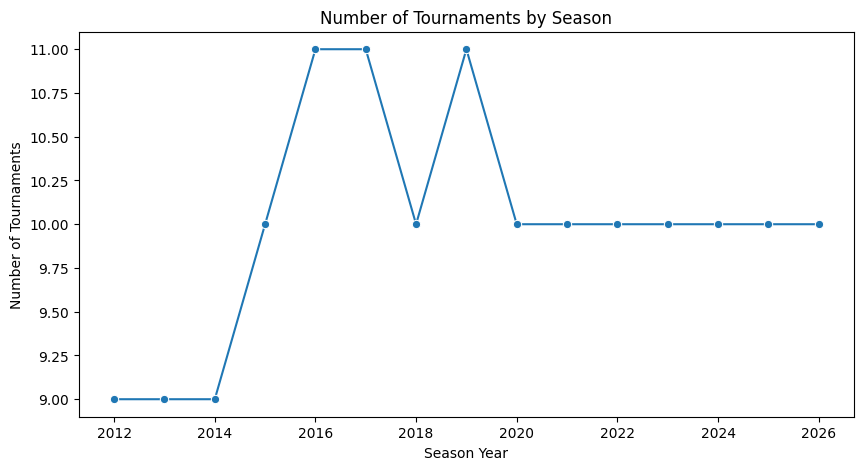

In [87]:
tournaments_per_year = (
    df.groupby("Season_Year")["Tournament_ID"]
      .nunique()
      .reset_index()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=tournaments_per_year,
    x="Season_Year",
    y="Tournament_ID",
    marker="o"
)

plt.title("Number of Tournaments by Season")
plt.xlabel("Season Year")
plt.ylabel("Number of Tournaments")

plt.show()

### Fishery Representation

Some fisheries appear repeatedly throughout the dataset while others were only visited once or twice.

Understanding this distribution helps identify fisheries with sufficient observations for later trend analyses.

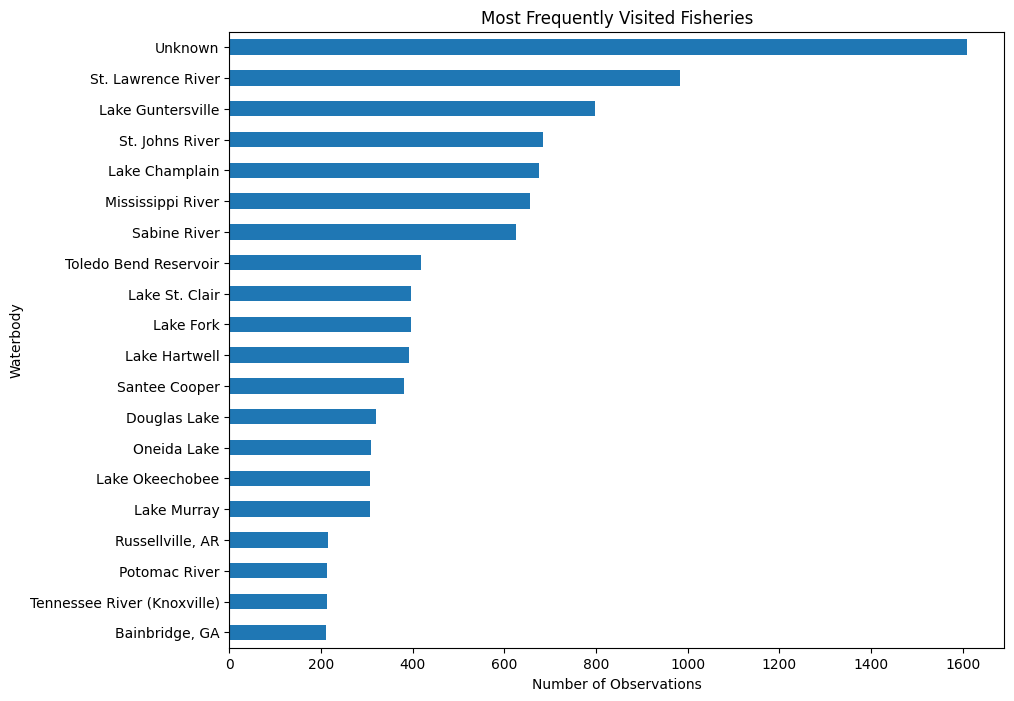

In [88]:
plt.figure(figsize=(10,8))

(
    df["Waterbody"]
      .value_counts()
      .head(20)
      .sort_values()
      .plot(kind="barh")
)

plt.title("Most Frequently Visited Fisheries")
plt.xlabel("Number of Observations")
plt.ylabel("Waterbody")

plt.show()

### Distribution of Fish Caught

The distribution of fish caught provides an initial look at tournament performance and catch success across all events in the dataset.

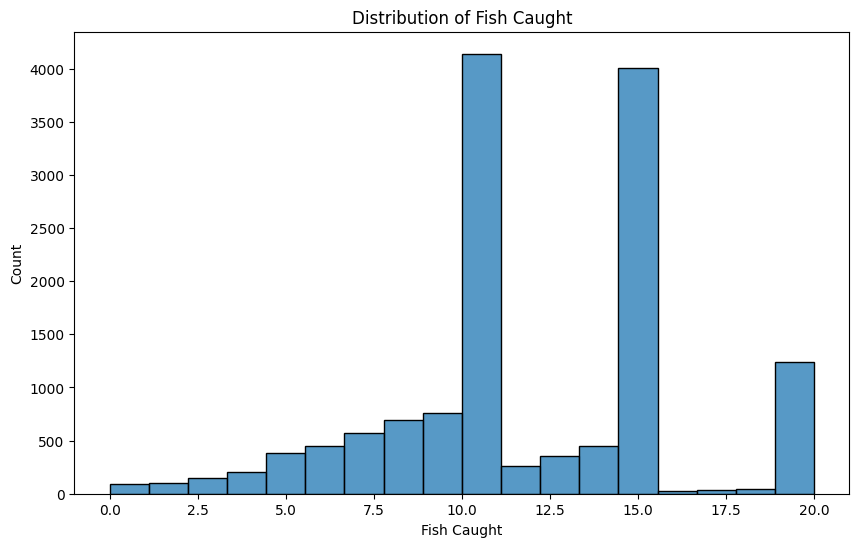

In [90]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Fish_Caught",
    bins=18
)

plt.title("Distribution of Fish Caught")
plt.xlabel("Fish Caught")
plt.ylabel("Count")

plt.show()

Several prominent peaks are visible throughout the distribution rather than a smooth continuous pattern.

These recurring peaks suggest that factors beyond fish abundance or angler performance may influence the reported number of fish caught. Additional investigation is warranted.

### Distribution of Tournament Weight

Tournament weight represents one of the primary performance metrics in bass fishing competitions.

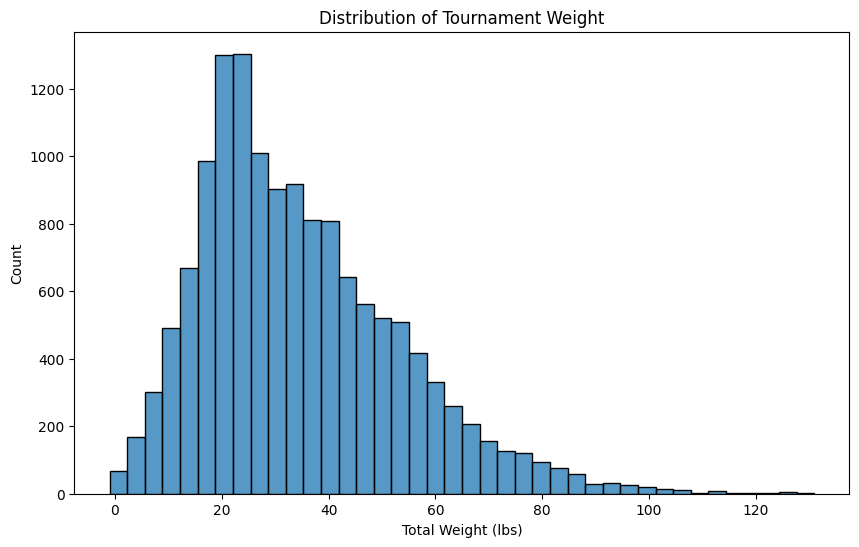

In [91]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Weight_Lbs_Calculated",
    bins=40
)

plt.title("Distribution of Tournament Weight")
plt.xlabel("Total Weight (lbs)")
plt.ylabel("Count")

plt.show()

Tournament weights exhibit a right-skewed distribution, with most observations concentrated within a relatively narrow range and fewer observations occurring at extremely high weights.

### Distribution of Average Fish Weight

Average fish weight was calculated as total tournament weight divided by the number of fish caught.

This variable provides a measure of fish size independent of total catch count.

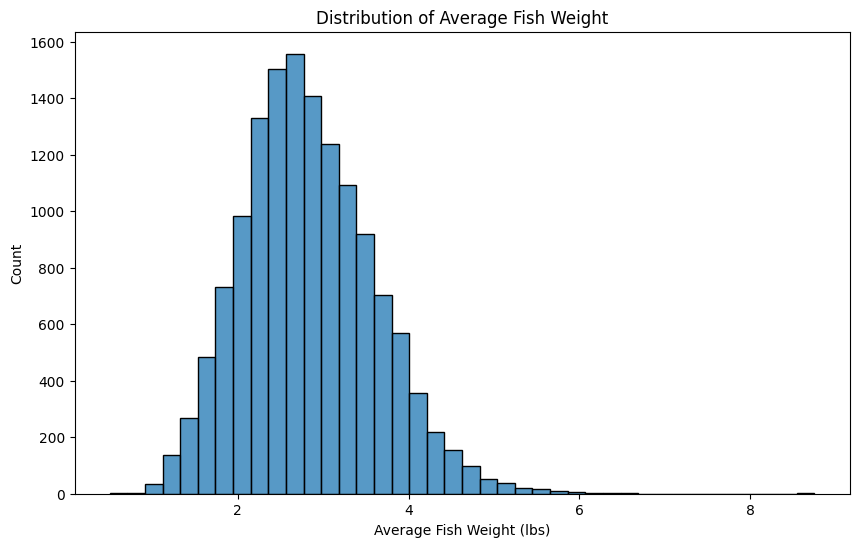

In [92]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Avg_Fish_Weight",
    bins=40
)

plt.title("Distribution of Average Fish Weight")
plt.xlabel("Average Fish Weight (lbs)")
plt.ylabel("Count")

plt.show()

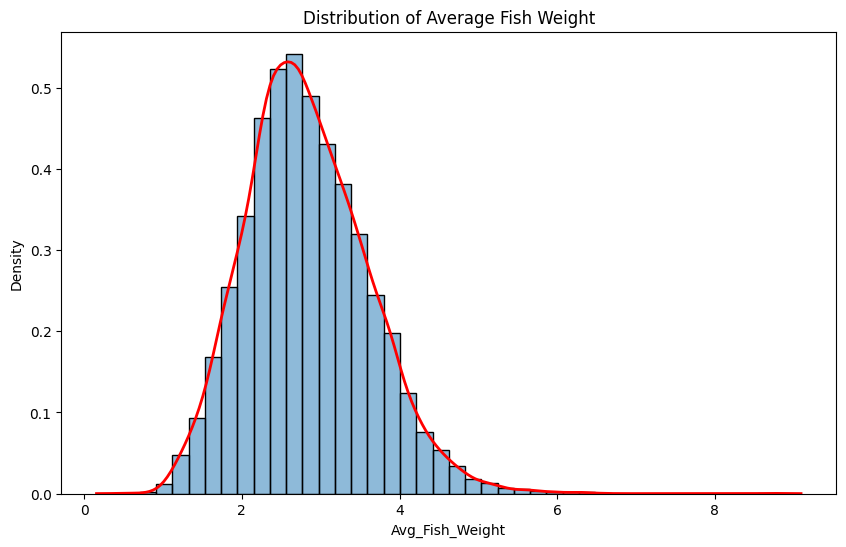

In [93]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Avg_Fish_Weight"],
    bins=40,
    stat="density",
    alpha=0.5
)

sns.kdeplot(
    df["Avg_Fish_Weight"],
    color="red",
    linewidth=2
)

plt.title("Distribution of Average Fish Weight")

plt.show()

### Distribution of FFS Categories

Before evaluating tournament outcomes, the relative representation of each FFS category was examined.

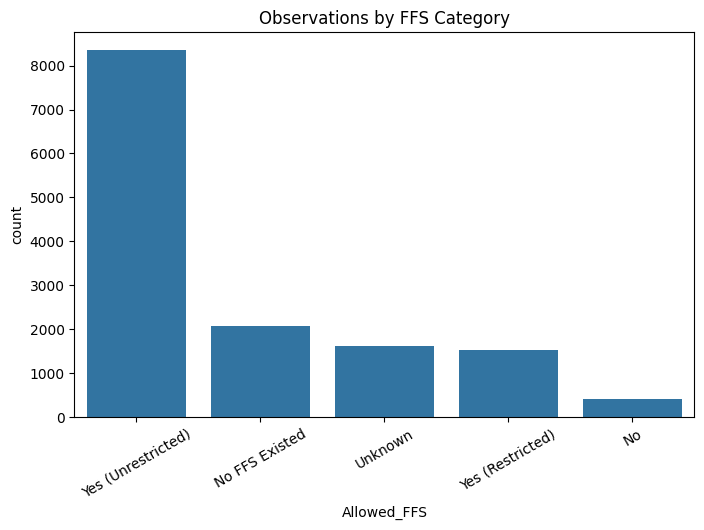

In [94]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Allowed_FFS",
    order=df["Allowed_FFS"].value_counts().index
)

plt.title("Observations by FFS Category")

plt.xticks(rotation=30)

plt.show()

### Initial Observations

Several patterns emerged during exploratory analysis:

1. Tournament weights and average fish weights appear broadly continuous and suitable for quantitative analysis.

2. Fish catch counts exhibit unusually strong peaks at specific values rather than a smooth distribution.

3. These peaks suggest that tournament rules or event structure may influence recorded catch counts.

Because these patterns could affect all subsequent analyses, the next section investigates tournament structure in greater detail.

# 5. Tournament Structure Effects

Initial exploratory analysis revealed strong evidence that tournament structure influences tournament outcomes.

Bassmaster Elite tournaments are typically conducted using a five-fish daily limit across multiple competition days. Consequently, tournaments of different durations produce different maximum allowable catches.

This has important implications:

- Raw fish counts are constrained by tournament duration.
- Average fish weight may increase in shorter tournaments because anglers can selectively retain larger fish.
- Comparisons among tournaments must account for differences in bag limits.

Before evaluating FFS effects, tournament structure must be examined as a potential source of variation.

In [66]:
bag_summary = (
    df.groupby("Bag_Limit")
      .agg({
          "Fish_Caught":["mean","median"],
          "Weight_Lbs_Calculated":["mean","median"],
          "Avg_Fish_Weight":["mean","median"]
      })
)

bag_summary

Fish_Caught        Weight_Lbs_Calculated           Avg_Fish_Weight  \
                 mean median                  mean    median            mean   
Bag_Limit                                                                      
10           8.940000   10.0             32.166250  34.34375        3.579292   
15          10.859189   11.0             32.731205  30.81250        2.920350   
20          11.906169   10.0             34.916110  31.25000        2.811224   

                     
             median  
Bag_Limit            
10         3.597321  
15         2.868750  
20         2.742188

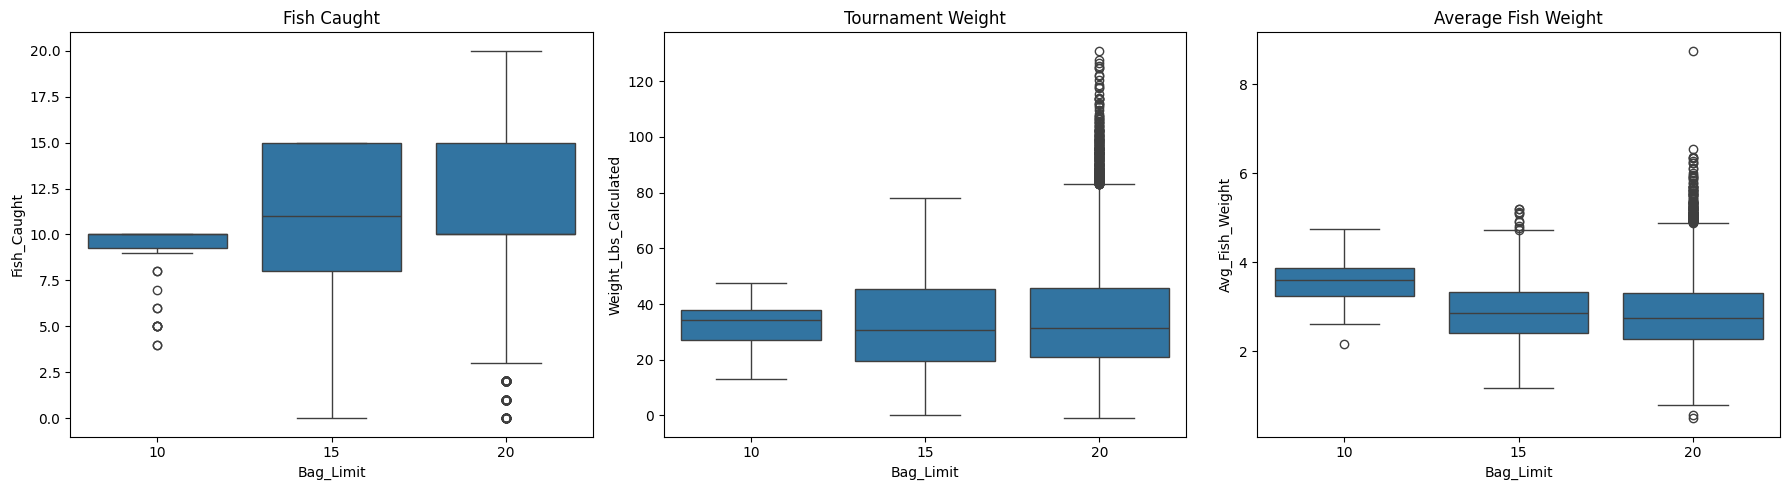

In [67]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18,5)
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Fish_Caught",
    ax=axes[0]
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Weight_Lbs_Calculated",
    ax=axes[1]
)

sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Avg_Fish_Weight",
    ax=axes[2]
)

axes[0].set_title("Fish Caught")
axes[1].set_title("Tournament Weight")
axes[2].set_title("Average Fish Weight")

plt.tight_layout()
plt.show()

### Initial Findings

Average fish weight varies substantially among tournament formats.

Although total catch weight remains relatively similar across bag limits, shorter tournaments tend to produce larger average fish weights. This pattern is consistent with increased opportunities for culling and high-grading catches.

These results suggest that tournament format is a potential confounding variable that should be included in subsequent analyses.

# 6. Standardizing Catch Success

Raw fish counts are difficult to compare across tournament formats because anglers in longer tournaments can accumulate more fish.

To allow comparisons among events, a standardized metric was created:

Percent of Limit Achieved

Fish Caught / Tournament Bag Limit

This metric places all tournaments on a common scale.

In [68]:
df["Pct_Limit"] = (
    df["Fish_Caught"] /
    df["Bag_Limit"]
)

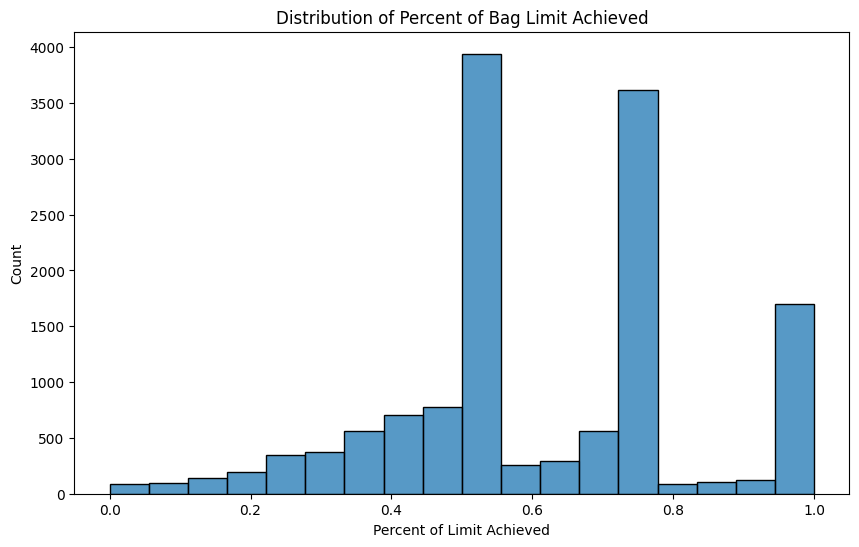

In [70]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Pct_Limit"],
    bins=18
)

plt.title("Distribution of Percent of Bag Limit Achieved")
plt.xlabel("Percent of Limit Achieved")
plt.ylabel("Count")

plt.show()


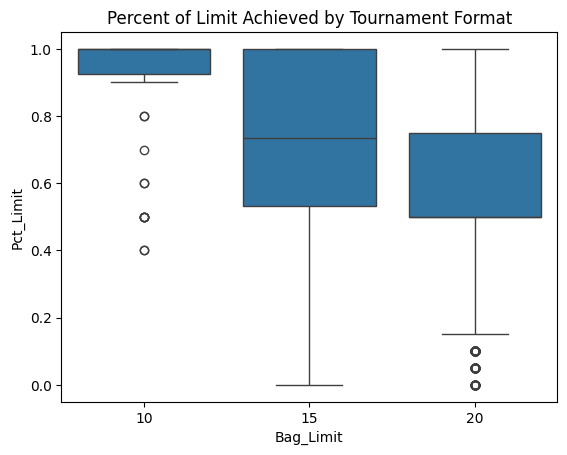

In [71]:
sns.boxplot(
    data=df,
    x="Bag_Limit",
    y="Pct_Limit"
)

plt.title("Percent of Limit Achieved by Tournament Format")

plt.show()

Percent of limit achieved provides a more meaningful measure of catch success than raw fish counts because it adjusts for differences in tournament duration.

# 7. Temporal Trends

Forward-facing sonar emerged during the late 2010s and rapidly spread throughout professional bass fishing.

This section examines whether tournament outcomes changed over time.

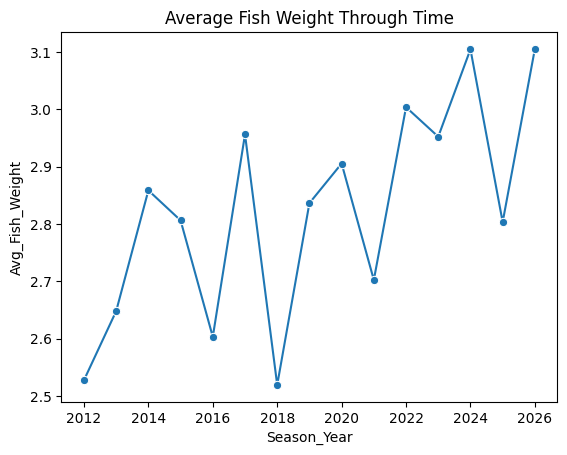

In [72]:
annual_size = (
    df.groupby("Season_Year")
      ["Avg_Fish_Weight"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_size,
    x="Season_Year",
    y="Avg_Fish_Weight",
    marker="o"
)

plt.title("Average Fish Weight Through Time")

plt.show()

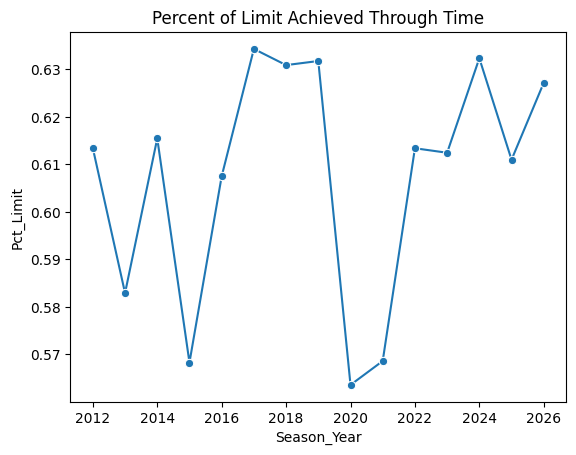

In [73]:
annual_limit = (
    df.groupby("Season_Year")
      ["Pct_Limit"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_limit,
    x="Season_Year",
    y="Pct_Limit",
    marker="o"
)

plt.title("Percent of Limit Achieved Through Time")

plt.show()

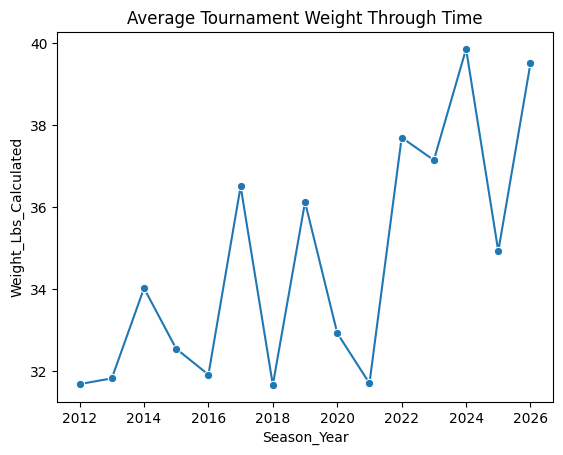

In [74]:
annual_weight = (
    df.groupby("Season_Year")
      ["Weight_Lbs_Calculated"]
      .mean()
      .reset_index()
)

sns.lineplot(
    data=annual_weight,
    x="Season_Year",
    y="Weight_Lbs_Calculated",
    marker="o"
)

plt.title("Average Tournament Weight Through Time")

plt.show()

# 8. Forward-Facing Sonar Comparisons

Having accounted for tournament structure, the next step is to examine whether tournament outcomes differ among FFS categories.

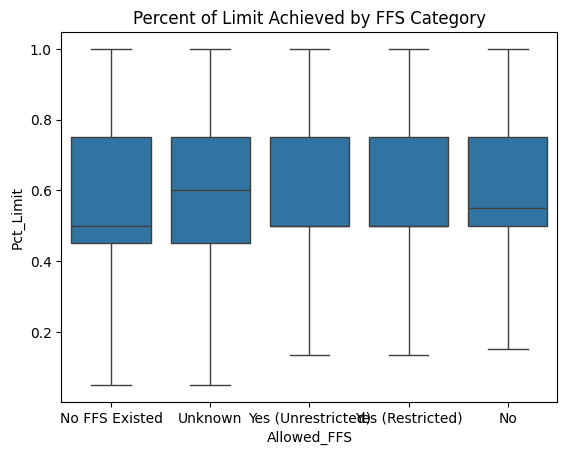

In [75]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Pct_Limit",
    showfliers=False
)

plt.title("Percent of Limit Achieved by FFS Category")

plt.show()

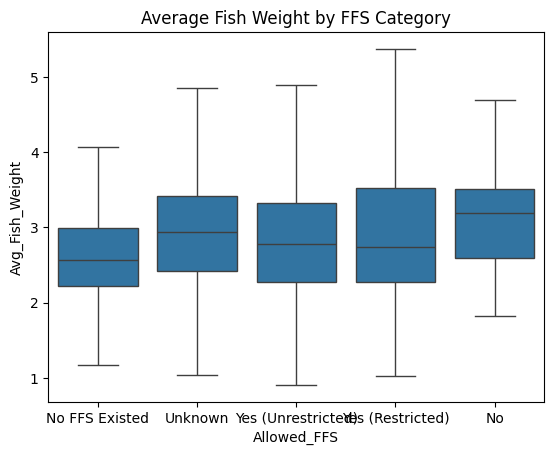

In [76]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    showfliers=False
)

plt.title("Average Fish Weight by FFS Category")

plt.show()

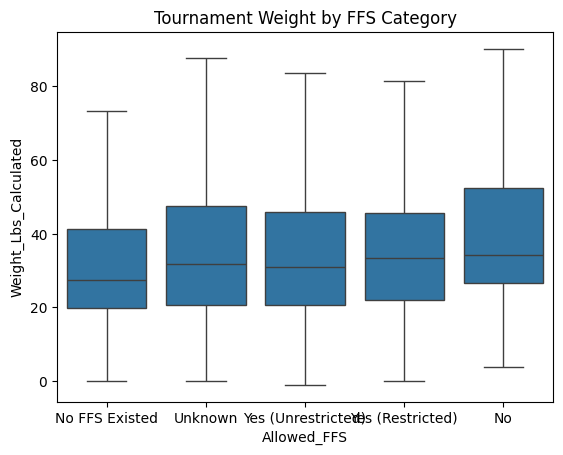

In [77]:
sns.boxplot(
    data=df,
    x="Allowed_FFS",
    y="Weight_Lbs_Calculated",
    showfliers=False
)

plt.title("Tournament Weight by FFS Category")

plt.show()

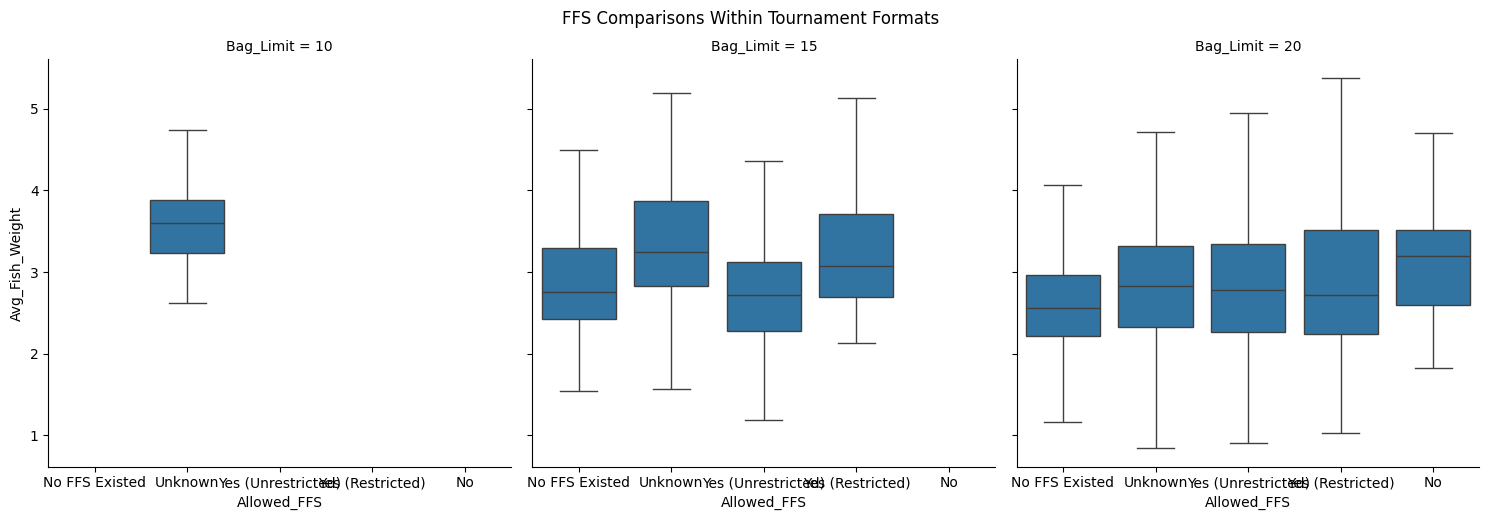

In [78]:
g = sns.catplot(
    data=df,
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    col="Bag_Limit",
    kind="box",
    showfliers=False,
    height=5,
    aspect=1
)

g.fig.suptitle(
    "FFS Comparisons Within Tournament Formats",
    y=1.03
)

plt.show()


# 9. Fishery-Specific Analysis

The impact of FFS is unlikely to be uniform across bass fisheries.

Clear-water systems with abundant suspended fish may respond differently than shallow vegetated systems.

This section investigates fishery-specific patterns.

### Top Fisheries

In [79]:
top_waterbodies = (
    df["Waterbody"]
      .value_counts()
      .head(10)
      .index
)

### Trends Through Time

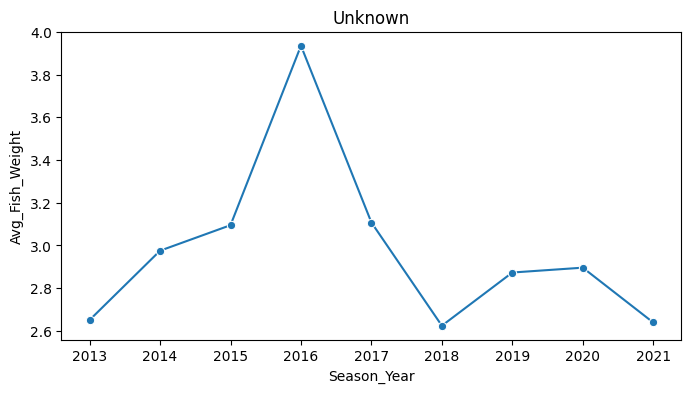

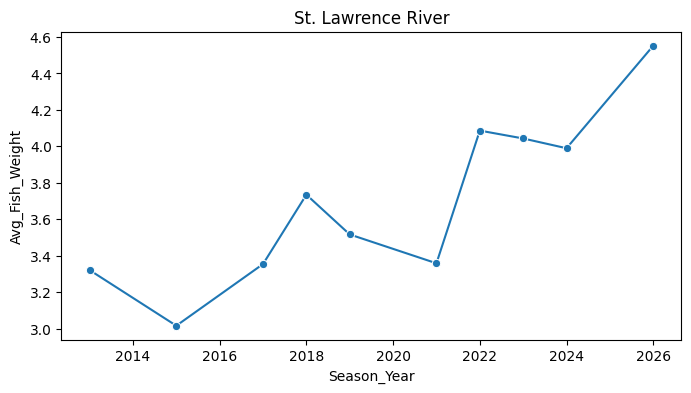

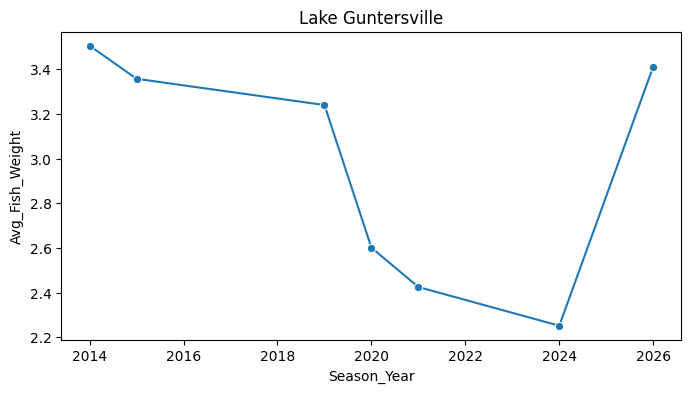

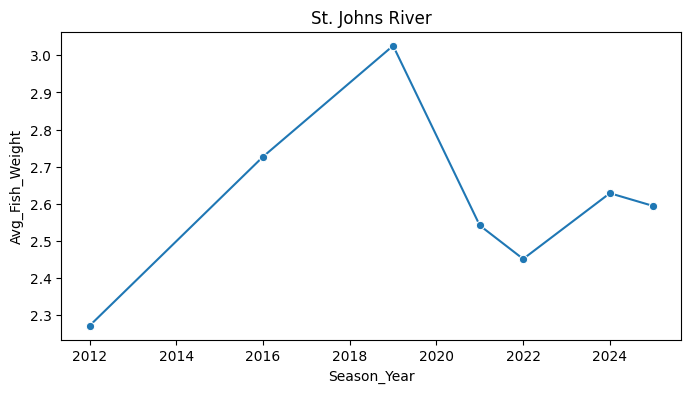

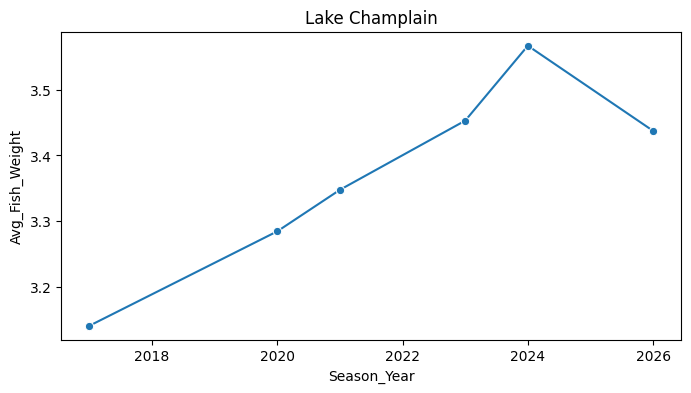

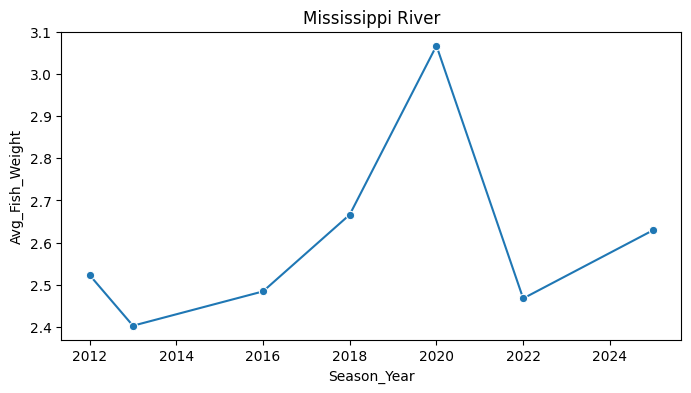

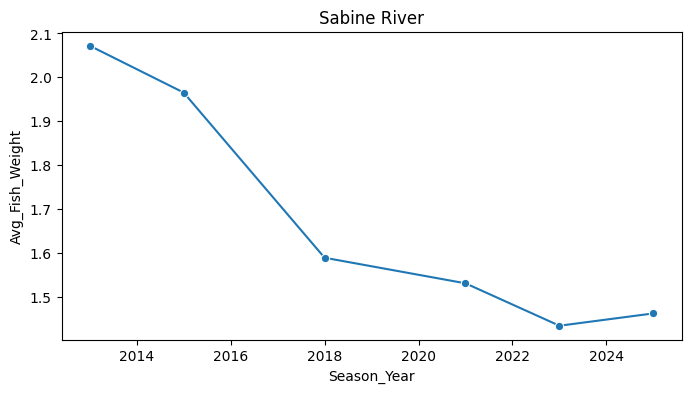

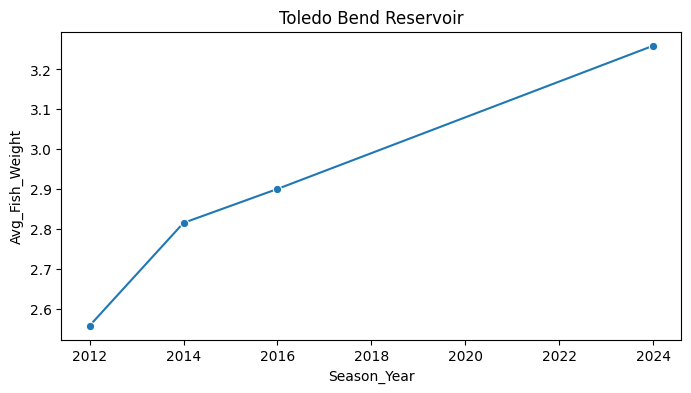

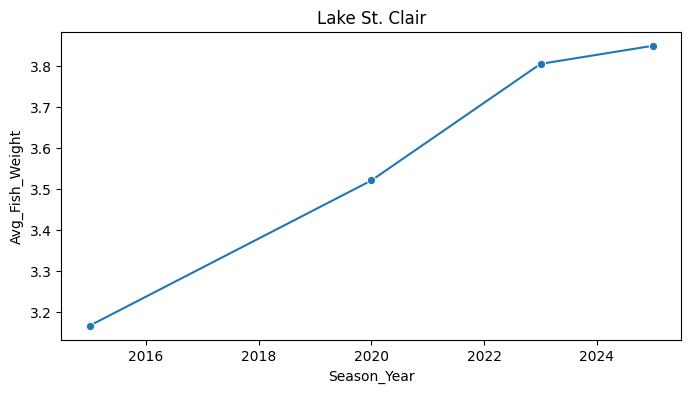

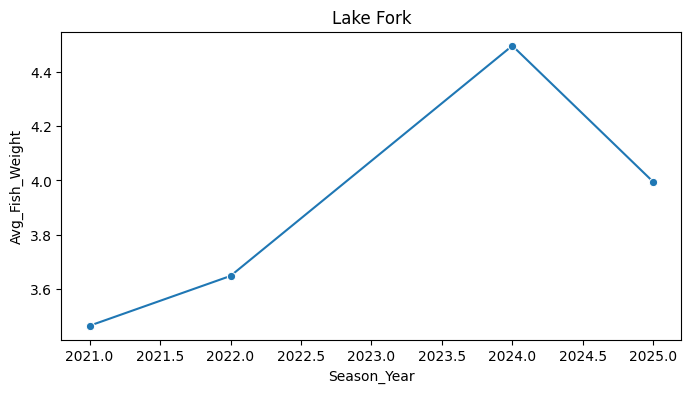

In [80]:
for wb in top_waterbodies:

    subset = df[df["Waterbody"] == wb]

    annual = (
        subset.groupby("Season_Year")
              ["Avg_Fish_Weight"]
              .mean()
              .reset_index()
    )

    plt.figure(figsize=(8,4))

    sns.lineplot(
        data=annual,
        x="Season_Year",
        y="Avg_Fish_Weight",
        marker="o"
    )

    plt.title(wb)

    plt.show()

### Fishery-Specific FFS Effects

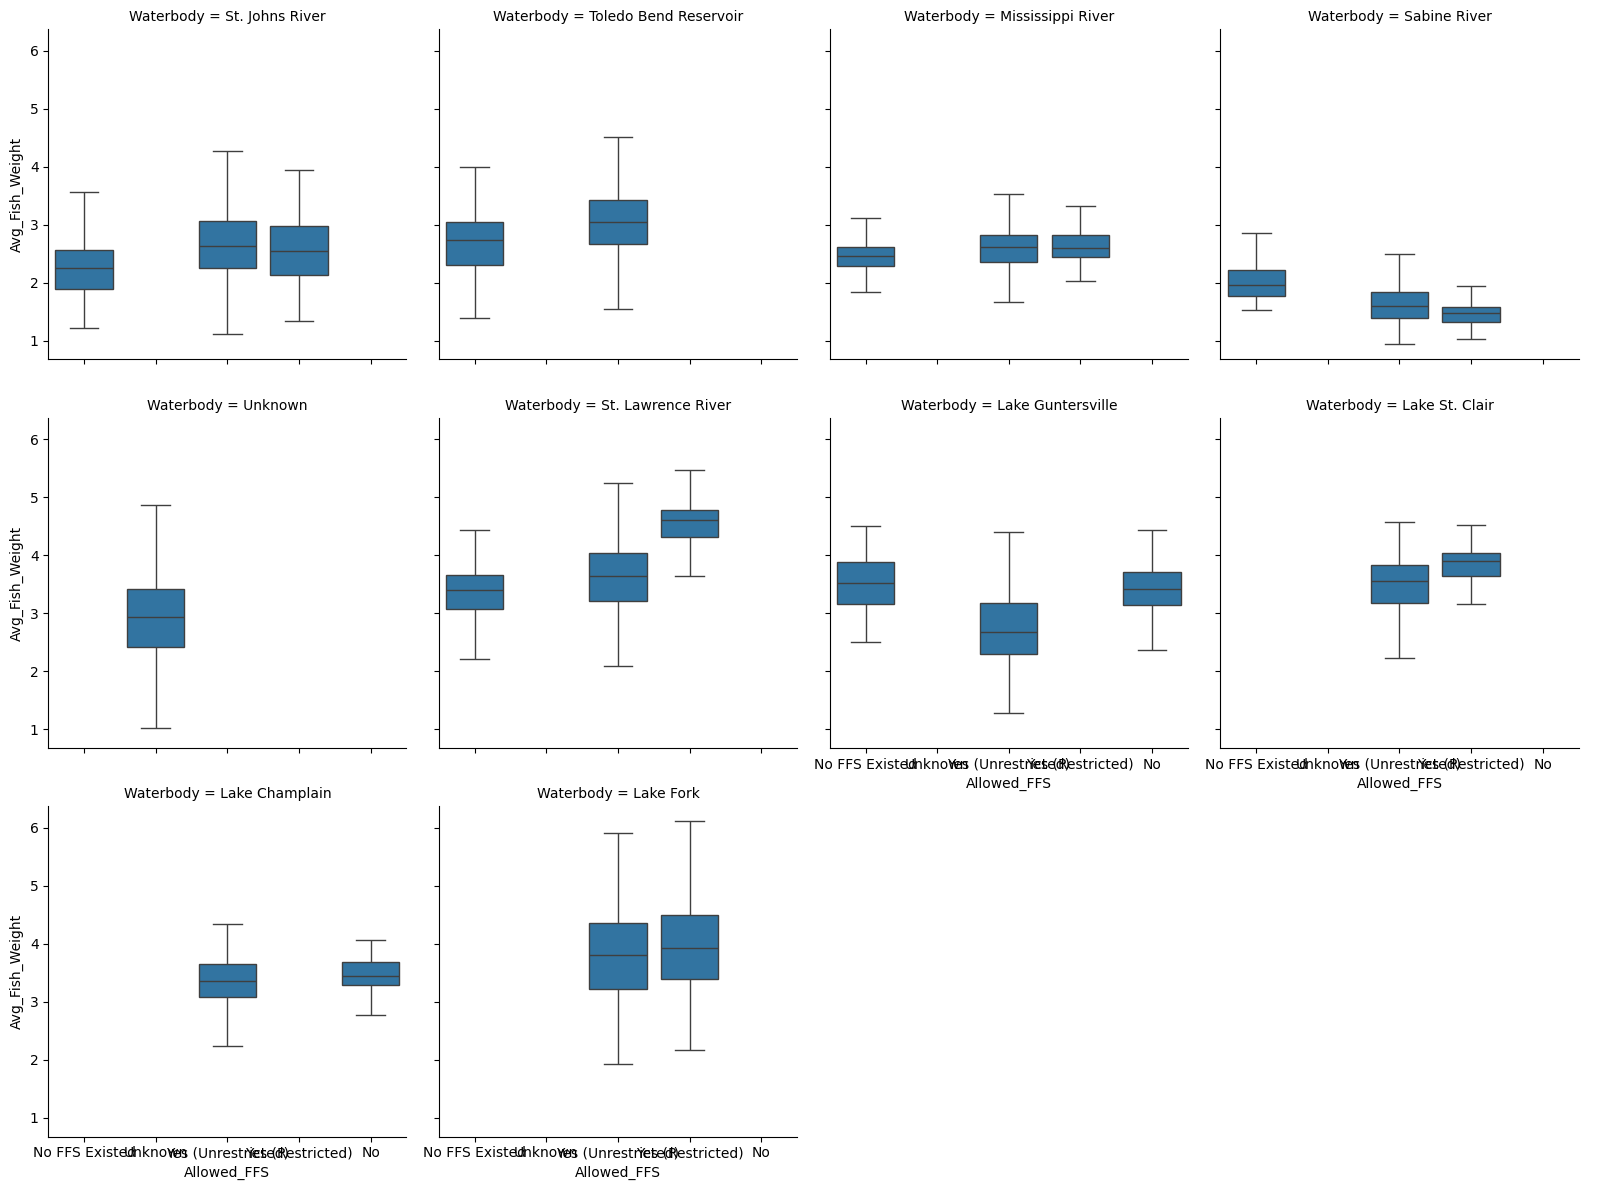

In [81]:
g = sns.catplot(
    data=df[df["Waterbody"].isin(top_waterbodies)],
    x="Allowed_FFS",
    y="Avg_Fish_Weight",
    col="Waterbody",
    col_wrap=4,
    kind="box",
    showfliers=False,
    height=4
)

plt.show()

# 10. Statistical Modeling

The goal of statistical modeling is to determine whether associations between FFS availability and tournament outcomes persist after accounting for tournament structure, time, and fishery differences.

### Model 1: Naive Model

In [82]:
model1 = smf.ols(
    "Avg_Fish_Weight ~ C(Allowed_FFS)",
    data=df
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:        Avg_Fish_Weight   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     55.11
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           3.53e-46
Time:                        11:59:19   Log-Likelihood:                -16082.
No. Observations:               13929   AIC:                         3.217e+04
Df Residuals:                   13924   BIC:                         3.221e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


### Model 2: Tournament Structure Adjusted

In [83]:
model2 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    """,
    data=df
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:        Avg_Fish_Weight   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     46.70
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           5.53e-57
Time:                        11:59:23   Log-Likelihood:                -16053.
No. Observations:               13929   AIC:                         3.212e+04
Df Residuals:                   13922   BIC:                         3.217e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


### Model 3: Full Fixed Effects Model

In [84]:
model3 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    + C(Waterbody)
    + Season_Year
    """,
    data=df
).fit()

print(model3.summary())


                            OLS Regression Results                            
Dep. Variable:        Avg_Fish_Weight   R-squared:                       0.469
Model:                            OLS   Adj. R-squared:                  0.466
Method:                 Least Squares   F-statistic:                     214.5
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:59:46   Log-Likelihood:                -11789.
No. Observations:               13929   AIC:                         2.369e+04
Df Residuals:                   13871   BIC:                         2.413e+04
Df Model:                          57                                         
Covariance Type:            nonrobust                                         
                                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------

/var/folders/5l/xbt3m1s500g44pgjwvtjq7xh0000gn/T/ipykernel_23061/2392494757.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


### Model 4: Mixed Effects Model

In [85]:
model4 = mixedlm(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    + C(Bag_Limit)
    + Season_Year
    """,
    groups=df["Waterbody"],
    data=df
)

results4 = model4.fit()

print(results4.summary())

PatsyError: factor contains missing values
    Avg_Fish_Weight     ~ C(Allowed_FFS)     + C(Bag_Limit)     + Season_Year
    ^^^^^^^^^^^^^^^

### Model 5: Interaction Model

In [86]:
model5 = smf.ols(
    """
    Avg_Fish_Weight
    ~ C(Allowed_FFS)
    * C(Waterbody)
    + C(Bag_Limit)
    + Season_Year
    """,
    data=df
).fit()

print(model5.summary())

                            OLS Regression Results                            
Dep. Variable:        Avg_Fish_Weight   R-squared:                       0.493
Model:                            OLS   Adj. R-squared:                  0.490
Method:                 Least Squares   F-statistic:                     168.5
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:00:53   Log-Likelihood:                -11456.
No. Observations:               13929   AIC:                         2.307e+04
Df Residuals:                   13848   BIC:                         2.369e+04
Df Model:                          80                                         
Covariance Type:            nonrobust                                         
                                                                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------

/var/folders/5l/xbt3m1s500g44pgjwvtjq7xh0000gn/T/ipykernel_23061/1678354966.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


# 11. Limitations

Several limitations affect interpretation of the results.

- The study is observational.
- FFS availability does not guarantee actual FFS use.
- Fishery health metrics were unavailable.
- Tournament formats varied across events.
- Tournament format was inferred from catch data.
- Other technological advances occurred during the study period.
- Environmental conditions were not included.

Consequently, results should be interpreted as associations rather than causal effects.

# 12. Conclusions

This analysis evaluated relationships between forward-facing sonar availability and Bassmaster Elite tournament outcomes from 2012–2026.

A key finding of the exploratory analysis was that tournament structure strongly influences catch statistics. Average fish weight differed considerably among tournament formats, highlighting the importance of accounting for bag limits before evaluating FFS effects.

After controlling for tournament structure, time, and fishery differences, the remaining analyses provide a more defensible assessment of the association between FFS availability and tournament performance.

Future work could incorporate environmental variables, fishery productivity metrics, and angler-level characteristics to further isolate drivers of tournament success.